In [1]:
# importing python modules
import os     
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from astropy import wcs, units
from astropy.io import fits
from astropy.cosmology import LambdaCDM
from astropy.constants import G
from scipy.optimize import curve_fit
from scipy.special import i0, i1, k0, k1
from sympy import Point, Line 

In [2]:
cube = fits.open('manga-8244-12704-LOGCUBE.fits.gz')    # assumes you are in the same directory as the cube file

# reading in and re-ordering FLUX, IVAR, and MASK arrays from (wavelength, y, x) to (x, y, wavelength).
flux = np.transpose(cube['FLUX'].data, axes=(2, 1, 0))
ivar = np.transpose(cube['IVAR'].data, axes=(2, 1, 0))
mask = np.transpose(cube['MASK'].data, axes=(2, 1, 0))

wave = cube['WAVE'].data   # reading in wavelength
flux_header = cube['FLUX'].header   # reading in the header of the flux extension

redshift = 0.115137   # redshift of this galaxy

In [3]:
print(flux.shape)   # should print (74, 74, 4563)
print(ivar.shape)   # should print (74, 74, 4563)
print(mask.shape)   # should print (74, 74, 4563)
print(wave.shape)   # should print (4563,)

(74, 74, 4563)
(74, 74, 4563)
(74, 74, 4563)
(4563,)


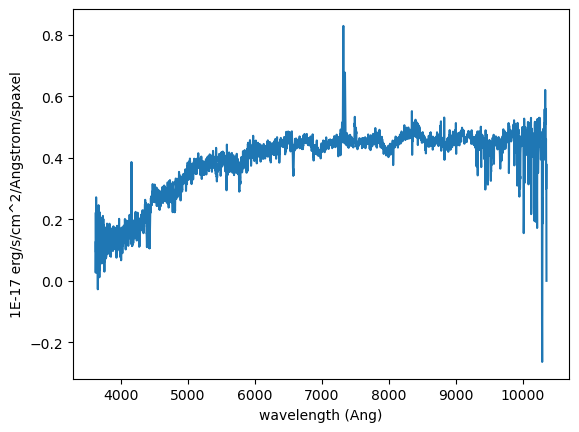

In [4]:
x_center = int(flux_header['CRPIX1']) - 1   # finding the middle pixel in x
y_center = int(flux_header['CRPIX2']) - 1   # finding the middle pixel in y

plt.plot(wave, flux[x_center, y_center])
plt.xlabel('wavelength (Ang)')
plt.ylabel(flux_header['BUNIT'])
plt.savefig('wave')
plt.show()

In [5]:
cubeWCS = wcs.WCS(flux_header)
ra = 229.525580000   # desired RA
dec = 42.7458420000  # desired dec
x_cube_coord, y_cube_coord, __ = cubeWCS.wcs_world2pix([[ra, dec, 1.]], 1)[0]
x_spaxel = int(np.round(x_cube_coord)) - 1  # corresponding x spaxel position
y_spaxel = int(np.round(y_cube_coord)) - 1  # corresponding x spaxel position

a string value was expected. [astropy.wcs.wcs]


In [6]:
do_not_use = (mask & 2**10) != 0   # finding the bad spaxels
flux_m = np.ma.array(flux, mask=do_not_use)  # new masked flux array
ivar_m = np.ma.array(ivar, mask=do_not_use)  # new masked ivar array

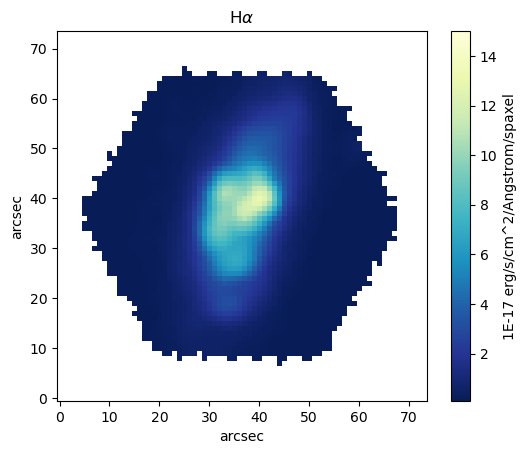

In [7]:
# finding the wavelegth range around H$\alpha$
halpha_wave = np.where((wave / (1 + redshift) > 6550) & (wave / (1 + redshift) < 6580))[0]

# summing the fluxes at each spaxel in the wavelength range
flux_sum = flux_m[:, :, halpha_wave].sum(axis=2)
im = flux_sum.T

# convert from array indices to arcsec relative to IFU center
dx = flux_header['CD1_1'] * 3600.  # deg to arcsec
dy = flux_header['CD2_2'] * 3600.  # deg to arcsec
x_extent = (np.array([0., im.shape[0]]) - (im.shape[0] - x_center)) * dx * (-1)
y_extent = (np.array([0., im.shape[1]]) - (im.shape[1] - y_center)) * dy

plt.imshow(im, cmap=cm.YlGnBu_r, vmin=0.1, vmax=15, origin='lower', interpolation='none')
plt.title(r'H$\alpha$')
plt.colorbar(label=flux_header['BUNIT'])
plt.xlabel('arcsec')
plt.ylabel('arcsec')
plt.savefig('halpha')
plt.show()

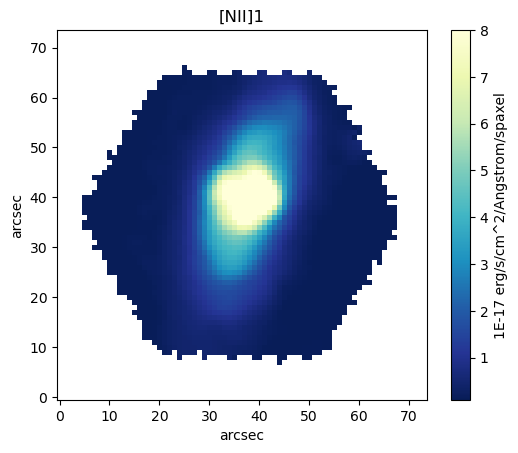

In [8]:
# finding the wavelegth range around [NII]1
NII1_wave = np.where((wave / (1 + redshift) > 6535) & (wave / (1 + redshift) < 6565))[0]

# summing the fluxes at each spaxel in the wavelength range
flux_sum = (flux_m[:, :, NII1_wave].sum(axis=2))  
im = flux_sum.T

# convert from array indices to arcsec relative to IFU center
dx = flux_header['CD1_1'] * 3600.  # deg to arcsec
dy = flux_header['CD2_2'] * 3600.  # deg to arcsec
x_extent = (np.array([0., im.shape[0]]) - (im.shape[0] - x_center)) * dx * (-1)
y_extent = (np.array([0., im.shape[1]]) - (im.shape[1] - y_center)) * dy

plt.imshow(im, cmap=cm.YlGnBu_r, vmin=0.1, vmax=8, origin='lower', interpolation='none')
plt.title("[NII]1")
plt.colorbar(label=flux_header['BUNIT'])
plt.xlabel('arcsec')
plt.ylabel('arcsec')
plt.savefig('NII_1')
plt.show()

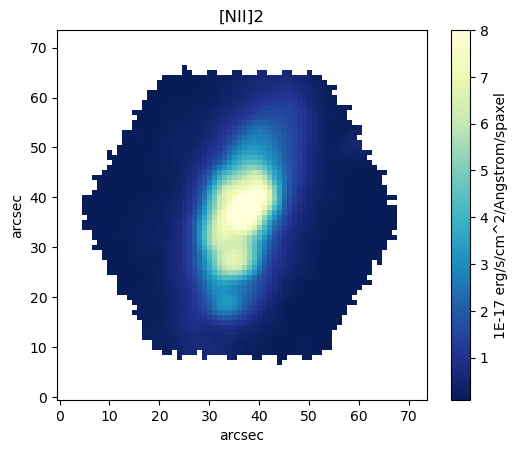

In [9]:
# finding the wavelegth range around [NII]2
NII2_wave = np.where((wave / (1 + redshift) > 6570) & (wave / (1 + redshift) < 6600))[0]

# summing the fluxes at each spaxel in the wavelength range
flux_sum = (flux_m[:, :, NII2_wave].sum(axis=2)) 
im = flux_sum.T

# convert from array indices to arcsec relative to IFU center
dx = flux_header['CD1_1'] * 3600.  # deg to arcsec
dy = flux_header['CD2_2'] * 3600.  # deg to arcsec
x_extent = (np.array([0., im.shape[0]]) - (im.shape[0] - x_center)) * dx * (-1)
y_extent = (np.array([0., im.shape[1]]) - (im.shape[1] - y_center)) * dy

plt.imshow(im, cmap=cm.YlGnBu_r, vmin=0.1, vmax=8, origin='lower', interpolation='none')
plt.title("[NII]2")
plt.colorbar(label=flux_header['BUNIT'])
plt.xlabel('arcsec')
plt.ylabel('arcsec')
plt.savefig('NII_2')
plt.show()

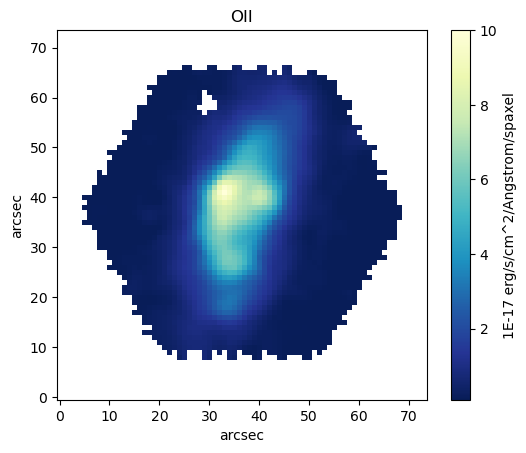

In [10]:
#finding the wavelegth range around OII
OII_wave = np.where((wave / (1 + redshift) > 3713) & (wave / (1 + redshift) < 3743))[0]  

#summing the fluxes at each spaxel in the wavelength range
flux_sum = (flux_m[:, :, OII_wave].sum(axis=2))
im = flux_sum.T

# convert from array indices to arcsec relative to IFU center
dx = flux_header['CD1_1'] * 3600.  # deg to arcsec
dy = flux_header['CD2_2'] * 3600.  # deg to arcsec
x_extent = (np.array([0., im.shape[0]]) - (im.shape[0] - x_center)) * dx * (-1)
y_extent = (np.array([0., im.shape[1]]) - (im.shape[1] - y_center)) * dy

plt.imshow(im, cmap=cm.YlGnBu_r, vmin=0.1, vmax=10, origin='lower', interpolation='none')
plt.title("OII")
plt.colorbar(label=flux_header['BUNIT'])
plt.xlabel('arcsec')
plt.ylabel('arcsec')
plt.savefig('OII')
plt.show()

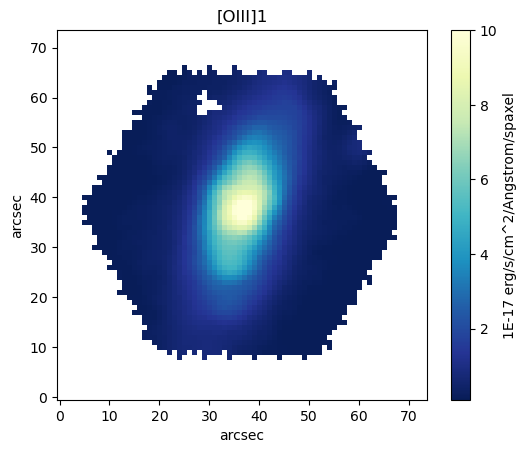

In [11]:
# finding the wavelegth range around [OIII]1
OIII1_wave = np.where((wave / (1 + redshift) > 4945) & (wave / (1 + redshift) < 4975))[0]  

# summing the fluxes at each spaxel in the wavelength range
flux_sum = (flux_m[:, :, OIII1_wave].sum(axis=2))
im = flux_sum.T

# convert from array indices to arcsec relative to IFU center
dx = flux_header['CD1_1'] * 3600.  # deg to arcsec
dy = flux_header['CD2_2'] * 3600.  # deg to arcsec
x_extent = (np.array([0., im.shape[0]]) - (im.shape[0] - x_center)) * dx * (-1)
y_extent = (np.array([0., im.shape[1]]) - (im.shape[1] - y_center)) * dy

plt.imshow(im, cmap=cm.YlGnBu_r, vmin=0.1, vmax=10, origin='lower', interpolation='none')
plt.title("[OIII]1")
plt.colorbar(label=flux_header['BUNIT'])
plt.xlabel('arcsec')
plt.ylabel('arcsec')
plt.savefig('OIII_1')
plt.show()

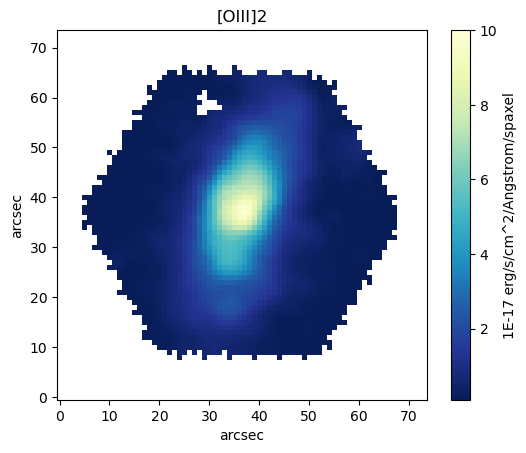

In [12]:
#finding the wavelegth range around [OIII]2 
OIII2_wave = np.where((wave / (1 + redshift) > 4993) & (wave / (1 + redshift) < 5023))[0]

#summing the fluxes at each spaxel in the wavelength range
flux_sum = (flux_m[:, :, OIII2_wave].sum(axis=2))
im = flux_sum.T

# Convert from array indices to arcsec relative to IFU center
dx = flux_header['CD1_1'] * 3600.  # deg to arcsec
dy = flux_header['CD2_2'] * 3600.  # deg to arcsec
x_extent = (np.array([0., im.shape[0]]) - (im.shape[0] - x_center)) * dx * (-1)
y_extent = (np.array([0., im.shape[1]]) - (im.shape[1] - y_center)) * dy

plt.imshow(im, cmap=cm.YlGnBu_r, vmin=0.1, vmax=10, origin='lower', interpolation='none')
plt.title("[OIII]2")
plt.colorbar(label=flux_header['BUNIT'])
plt.xlabel('arcsec')
plt.ylabel('arcsec')
plt.savefig('OIII_2')
plt.show()

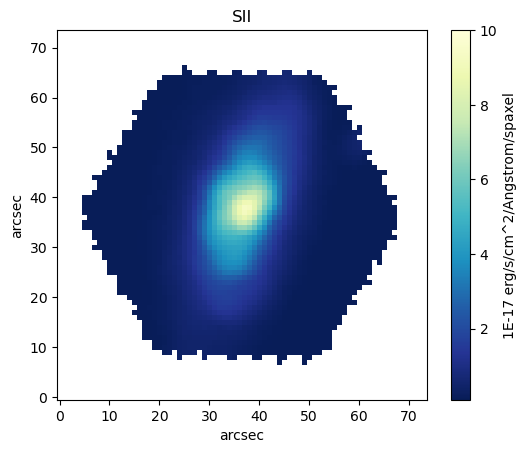

In [13]:
# finding the wavelegth range around SII
SII_wave = np.where((wave / (1 + redshift) > 6708) & (wave / (1 + redshift) < 6738))[0]  

# summing the fluxes at each spaxel in the wavelength range
flux_sum = (flux_m[:, :, SII_wave].sum(axis=2))
im = flux_sum.T

# convert from array indices to arcsec relative to IFU center
dx = flux_header['CD1_1'] * 3600.  # deg to arcsec
dy = flux_header['CD2_2'] * 3600.  # deg to arcsec
x_extent = (np.array([0., im.shape[0]]) - (im.shape[0] - x_center)) * dx * (-1)
y_extent = (np.array([0., im.shape[1]]) - (im.shape[1] - y_center)) * dy

plt.imshow(im, cmap=cm.YlGnBu_r, vmin=0.1, vmax=10, origin='lower', interpolation='none')
plt.title("SII")
plt.colorbar(label=flux_header['BUNIT'])
plt.xlabel('arcsec')
plt.ylabel('arcsec')
plt.savefig('SII')
plt.show()

In [14]:
# model for fitting flux as a function of wavelength
def modelFluxWavelength(x, C, peakHalpha, peakNII1, peakNII2, sigma, z):
    restHalpha = 6564.6
    restNII1 = 6549.9
    restNII2 = 6585.3
    
    return(C + (peakHalpha * np.exp(-((x - (restHalpha * (1 + z)))**2 / (2 * (sigma)**2))))
            + (peakNII1 * np.exp(-((x - (restNII1 * (1 + z)))**2 / (2 * (sigma)**2))))
            + (peakNII2 * np.exp(-((x - (restNII2 * (1 + z)))**2 / (2 * (sigma)**2)))))

# fitting function for one spaxel
def fitFluxWavelength(spaxel):
    # initial values
    guess = [0.1,
             np.max(flux_m[*spaxel, waveBound]), 
             np.max(flux_m[*spaxel, waveBound])/2, 
             np.max(flux_m[*spaxel, waveBound])/2, 
             3, 
             redshift]
    
    # parameter bounds
    C_b = [0.0,1.0]
    A_Halpha_b = [0.0, (guess[1]*3)]
    A_NII1_b = [0.0, (guess[2]*3)]
    A_NII2_b = [0.0, (guess[3]*3)]
    sigma_b = [1.0,5.0]
    z_b = [(guess[5]-0.01),(guess[5]+0.01)]

    lower = [C_b[0], A_Halpha_b[0], A_NII1_b[0], A_NII2_b[0], sigma_b[0], z_b[0]]
    upper = [C_b[1], A_Halpha_b[1], A_NII1_b[1], A_NII2_b[1], sigma_b[1], z_b[1]]

    x = wave[waveBound]
    y = flux_m[*spaxel, waveBound]

    fitParam, fitCov = curve_fit(modelFluxWavelength, x, y, p0 = guess, 
                           sigma = fluxErr[*spaxel, waveBound], absolute_sigma = True, bounds = (lower, upper))
    return(fitParam, fitCov)

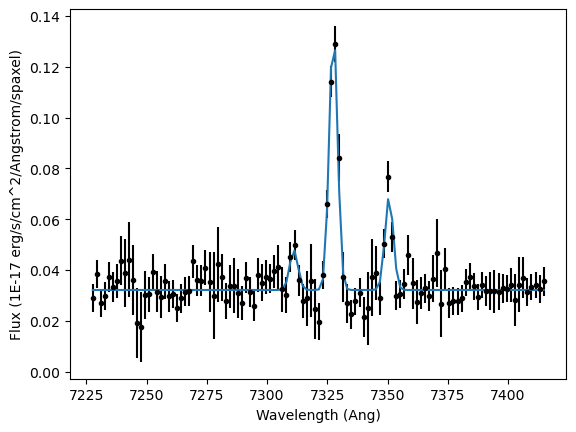

[0.03217836 0.10276226 0.01571295 0.03680265 1.71917944 0.11621906]
[6.89929186e-04 5.91810680e-03 4.55473909e-03 4.65465656e-03
 1.15391339e-01 1.73831526e-05]


In [15]:
# curve of best fit for central spaxel
waveBound = np.where((wave / (1 + redshift) > 6480) & (wave / (1 + redshift) < 6650))[0]
fluxErr = (1 / np.sqrt(ivar_m))
spaxel = [30, 15]

fitParam, fitCov = fitFluxWavelength(spaxel)

x = wave[waveBound]
y = flux_m[*spaxel, waveBound]
fluxFit = modelFluxWavelength(x, *fitParam)

plt.errorbar(x, y, yerr=(fluxErr[*spaxel, waveBound]), fmt='k.')
plt.plot(x, fluxFit)
plt.xlabel('Wavelength (Ang)')
plt.ylabel('Flux ('+ flux_header['BUNIT'] + ')')
plt.savefig('fluxwave')
plt.show()

print(fitParam)
print(np.sqrt(np.diag(fitCov)))

In [16]:
# fitting for all relevant spaxels [0=C, 1,2,3=peak, 4=sigma, 5=z]
fitsParam = np.zeros((74,74,6))
fitsErr = np.zeros((74,74,6))

for i in range(74):
    for j in range(74):
        try:
            spaxel = [i,j]
            fitParam, fitCov = fitFluxWavelength(spaxel)
            fitsParam[i][j], fitsErr[i][j] = fitParam, np.sqrt(np.diag(fitCov))
        except:
            for k in range(6):
                fitsParam[i][j][k], fitsErr[i][j][k] = np.nan, np.nan

C:\Users\Xincl\Documents\Apps\Anaconda\Lib\site-packages\numpy\core\shape_base.py:65: UserWarning: Warning: converting a masked element to nan.
  ary = asanyarray(ary)
C:\Users\Xincl\Documents\Apps\Anaconda\Lib\site-packages\scipy\optimize\_lsq\least_squares.py:96: UserWarning: Warning: converting a masked element to nan.
  lb, ub = (np.asarray(b, dtype=float) for b in bounds)
C:\Users\Xincl\Documents\Apps\Anaconda\Lib\site-packages\scipy\optimize\_minpack_py.py:931: RuntimeWarning: divide by zero encountered in divide
  transform = 1.0 / sigma


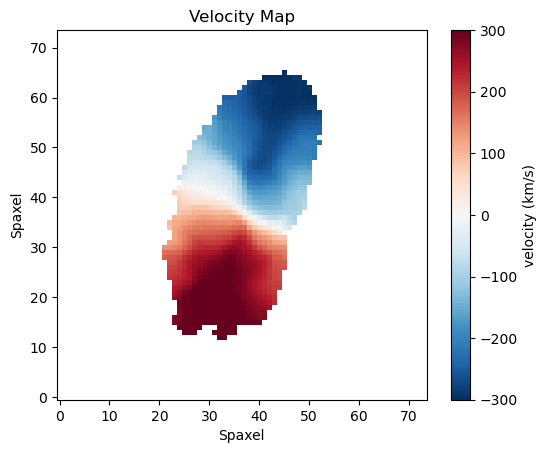

In [17]:
# converting z values into a line of sight velocity km/s dependent on S/N cut
vLos = np.zeros((74,74))

for i in range(74):
    for j in range(74):
        if ((fitsParam[i][j][1]/fitsErr[i][j][1]) > 5 and (fitsParam[i][j][3]/fitsErr[i][j][3]) > 3 and
            (fitsParam[i][j][1]) > (3*fitsErr[i][j][0])):
            vLos[i][j] = (fitsParam[i][j][5] - redshift) * 300000
        else:
            vLos[i][j] = np.nan

# plotting velocity map
im = vLos.T

plt.imshow(im, cmap=cm.RdBu_r, vmin=-300, vmax=300, origin='lower', interpolation='none')
plt.title("Velocity Map")
plt.colorbar(label=('velocity (km/s)'))
plt.xlabel('Spaxel')
plt.ylabel('Spaxel')
plt.savefig('velocity_map')
plt.show()

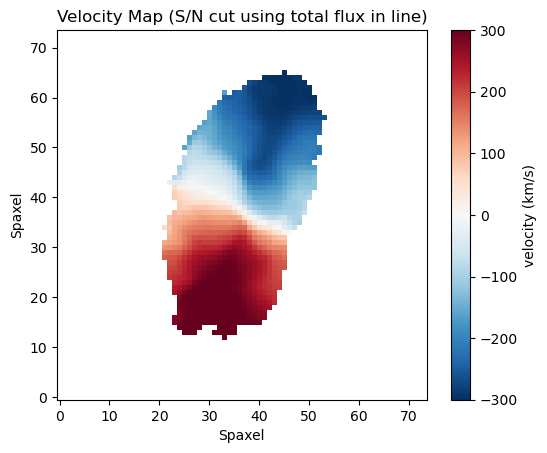

In [18]:
# converting z values into a line of sight velocity km/s dependent on S/N cut
vLos = np.zeros((74,74))

for i in range(74):
    for j in range(74):
        if ((((3 * fitsParam[i][j][4] * fitsParam[i][j][3])) / 
             (3 * ((fitsErr[i][j][4]/fitsParam[i][j][4]) + (fitsErr[i][j][3]/fitsParam[i][j][3])))) > 0.05 and 
            (((3 * fitsParam[i][j][4] * fitsParam[i][j][1])) / 
             (3 * ((fitsErr[i][j][4]/fitsParam[i][j][4]) + (fitsErr[i][j][1]/fitsParam[i][j][1])))) > 0.1):
            vLos[i][j] = (fitsParam[i][j][5] - redshift) * 300000
        else:
            vLos[i][j] = np.nan

# plotting velocity map
im = vLos.T

plt.imshow(im, cmap=cm.RdBu_r, vmin=-300, vmax=300, origin='lower', interpolation='none')
plt.title("Velocity Map (S/N cut using total flux in line)")
plt.colorbar(label=('velocity (km/s)'))
plt.xlabel('Spaxel')
plt.ylabel('Spaxel')
plt.savefig('velocity_map_totalflux.png')
plt.show()

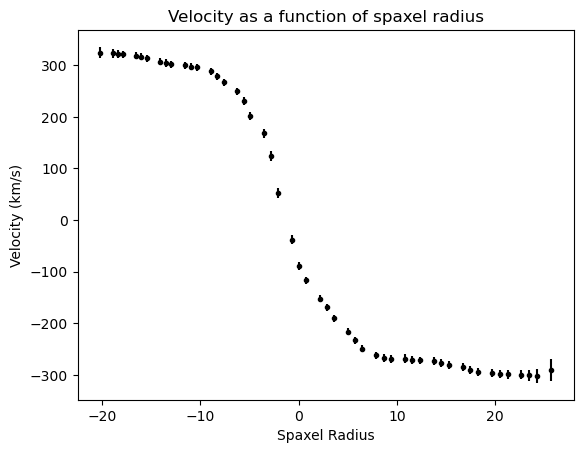

In [19]:
# finding spaxel that lies on the major axis
v = [] # line of sight velocity along the major axis
r = [] # spaxel radius
e = [] # velocity error

p1 = Point(30, 14)
p2 = Point(47, 64)
pc = Point(38, 38)
distCtr = np.sqrt(int((pc[0])**2 + (pc[1])**2))

line = Line(p1,pc,p2)

# Collecting velocities of spaxel near the major axis
for i in range(74):
    for j in range(74):  
        if np.isnan(vLos[i][j]) != True and line.distance(Point(i,j)) < 0.6:
            v.append(vLos[i][j])
            r.append(np.sqrt(i**2 + j**2))
            e.append(fitsErr[i][j][5]) 
            
ind = np.argsort(r)

vMajor = np.array(v)[ind]
rSpaxel = np.array(r)[ind]
vErr = (np.array(e)[ind] + 0.000019) * 300000
            
plt.errorbar(rSpaxel - distCtr, vMajor, yerr=vErr, fmt='k.')
plt.title("Velocity as a function of spaxel radius")
plt.xlabel('Spaxel Radius')
plt.ylabel('Velocity (km/s)')
plt.savefig('velocity_spaxel')
plt.show()

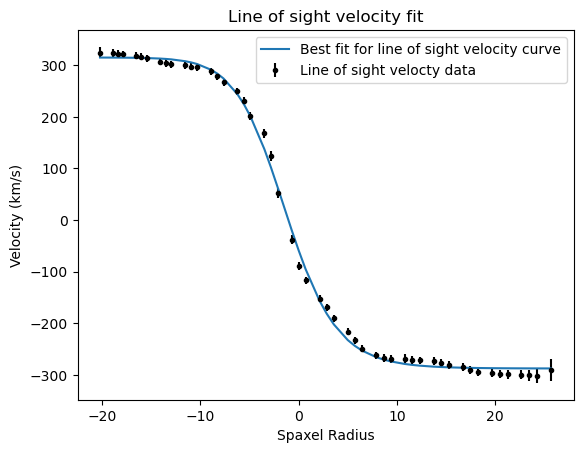

[ 314.99739994   20.32127853   52.45782727 -287.69742769]


In [35]:
# velocity data model for fitting
def modelVelocity(x, a, b, c, d):
    return(((a-d) / (1 + (x/c)**b)) + d)

fitParam, fitCov = curve_fit(modelVelocity, rSpaxel, vMajor)

vMajorFit = modelVelocity(rSpaxel, *fitParam)

line1 = plt.errorbar(rSpaxel - distCtr, vMajor, yerr=vErr, fmt='k.', label='Line of sight velocty data')
line2, = plt.plot(rSpaxel - distCtr, vMajorFit, label='Best fit for line of sight velocity curve')
plt.legend()
plt.title("Line of sight velocity fit")
plt.xlabel('Spaxel Radius')
plt.ylabel('Velocity (km/s)')
plt.savefig('velocity_fit')
plt.show()

print(fitParam)

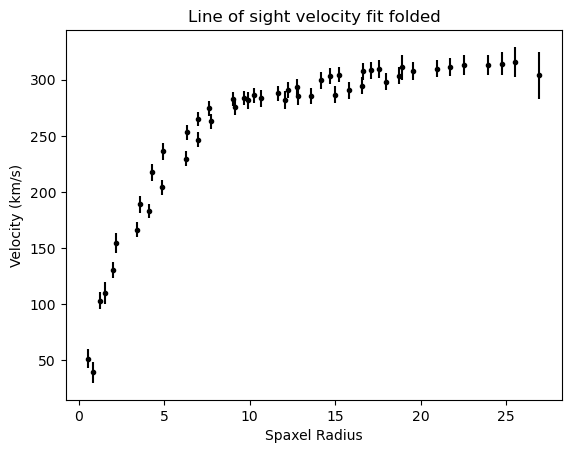

In [21]:
# folding velocity data 
a, b, c, d = fitParam

rFold = np.abs(rSpaxel - c)
vFold = np.abs(vMajor - (0.5*(a+d)))

plt.errorbar(rFold, vFold, yerr=vErr, fmt='k.')
plt.title("Line of sight velocity fit folded")
plt.xlabel('Spaxel Radius')
plt.ylabel('Velocity (km/s)')
plt.savefig('velocity_fold')
plt.show()

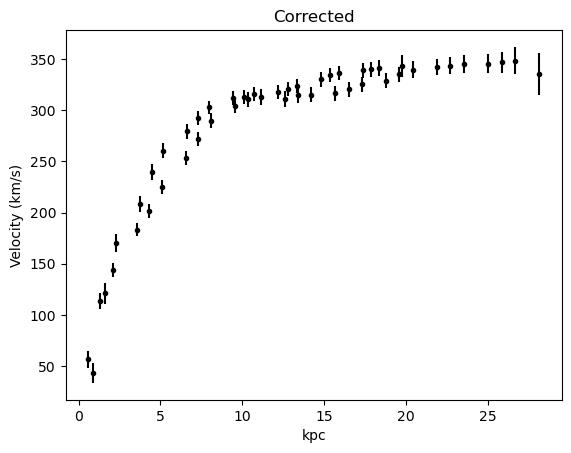

In [22]:
# correcting velocity data
cosmo = LambdaCDM(H0=70 * units.km / units.s / units.Mpc, Om0=0.3, Ode0=0.7)

i = np.deg2rad(65.07)
vCorrected = vFold / np.sin(i)

arcsecPerKpc = cosmo.arcsec_per_kpc_proper(redshift)
rFoldKpc = rFold * 0.5 * units.arcsec / arcsecPerKpc

plt.errorbar(rFoldKpc, vCorrected, yerr=vErr, fmt='k.')
plt.title("Corrected")
plt.xlabel('kpc')
plt.ylabel('Velocity (km/s)')
plt.savefig('velocity_fold_corr')
plt.show()

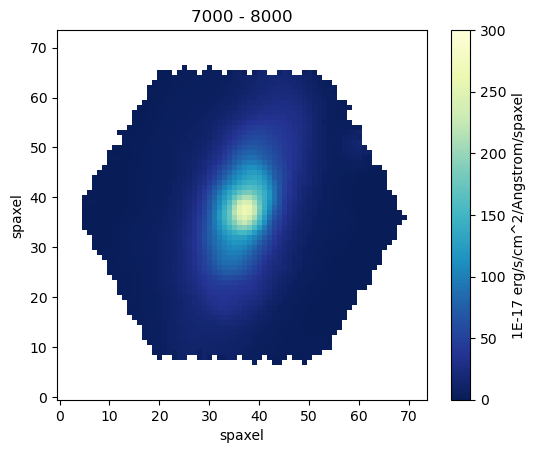

In [23]:
waveBound = np.where((wave / (1 + redshift) > 7000) & (wave / (1 + redshift) < 8000))[0]

# summing the fluxes at each spaxel in the wavelength range
fluxSum = (flux_m[:, :, waveBound].sum(axis=2))
im = fluxSum.T

plt.imshow(im, cmap=cm.YlGnBu_r, vmin=0, vmax=300, origin='lower', interpolation='none')
plt.title("7000 - 8000")
plt.colorbar(label=flux_header['BUNIT'])
plt.xlabel('spaxel')
plt.ylabel('spaxel')
plt.savefig('flux_map')
plt.show()     

In [24]:
# surface brightness model
def modelSurfaceBrightness(r, I0, rDisc):
    return(I0 * np.exp(-r/rDisc))

sBright = []
sBrightErr = []

# collecting surface brightnes along major axis
for i in range(74):
    for j in range(74):  
        if np.isnan(vLos[i][j]) != True and line.distance(Point(i,j)) < 0.6:
            sBright.append(fluxSum[i][j])
            sBrightErr.append(fluxErr[i][j][waveBound].sum(axis=0))
            
sBright = (np.array(sBright) * 1e-17)
sBrightErr = (np.array(sBrightErr) * 1e-17)

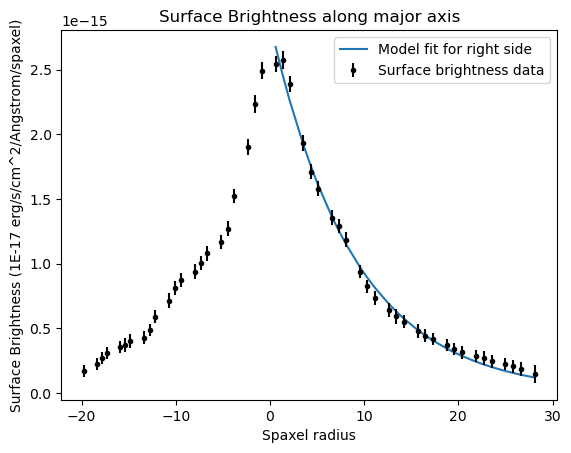

array([2.86514498e-15, 8.85938084e+00])

In [31]:
#converting units and plotting surface brightness
rKpc = ((((rSpaxel - c) * 0.5 * units.arcsec) / arcsecPerKpc)).to_value()

rKpcRight = rKpc[np.where(rSpaxel - c > 0)[0]]
sBrightRight = sBright[np.where(rSpaxel - c > 0)[0]]

fitParam, fitCov = curve_fit(modelSurfaceBrightness, rKpcRight, sBrightRight)
sBrightFit = modelSurfaceBrightness(rKpcRight, *fitParam)

line1, = plt.plot(rKpcRight, sBrightFit, label='Model fit for right side')
line2 = plt.errorbar(rKpc, sBright, yerr=sBrightErr, fmt='k.', label='Surface brightness data')
plt.legend() 
plt.title("Surface Brightness along major axis")
plt.xlabel('Spaxel radius')
plt.ylabel('Surface Brightness (' + flux_header['BUNIT'] + ')')
plt.savefig('surface_brightness')
plt.show()

fitParam

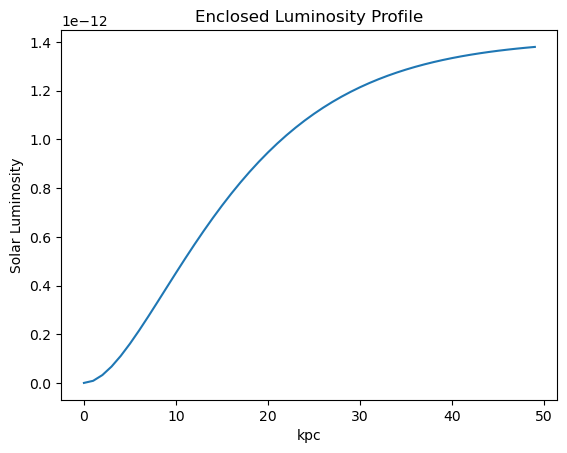

In [30]:
# plotting enclosed luminosity profile
I0, rDisc = fitParam
r = np.linspace(0,50, num = 50)

def profileEncLum(r):
    return(2 * np.pi * I0 * rDisc**2 * (1 - np.exp(-(r/rDisc)) * (1 + (r/rDisc))))
    
plt.plot(profileEncLum(r))
plt.title("Enclosed Luminosity Profile")
plt.xlabel('kpc')
plt.ylabel('Solar Luminosity')
plt.savefig('enclosed_lum_prof')
plt.show()

In [36]:
I0units = I0 * units.erg / (units.s * units.cm**2 * units.AA)

lumSun = 3.828e33 * units.erg / units.s

# integrate over waveBound
Delta_lambda_rest = 1000.0 * units.AA
Delta_lambda_obs  = Delta_lambda_rest * (1 + redshift)
fBand = I0units * Delta_lambda_obs  # erg/s/cm^2 per spaxel

# flux to luminosity per spaxel
distLum = cosmo.luminosity_distance(redshift)    # Mpc
distLumCm = distLum.to(units.cm)
lumBand = 4 * np.pi * distLumCm**2 * fBand   # erg/s per spaxel

# convert to lumSun per spaxel
lumBandLSun = (lumBand / lumSun).decompose()   # Lsun per spaxel

# divide by spaxel physical area to get surface brightness in Lsun/kpc^2
spaxel_size = 0.5 * units.arcsec
kpc_per_arcsec = (cosmo.kpc_proper_per_arcmin(redshift) / 60.0).to(units.kpc/units.arcsec)
spaxel_phys = (spaxel_size * kpc_per_arcsec).to(units.kpc)
A_spaxel = (spaxel_phys**2).to(units.kpc**2)

I0LSunPerKpc2 = (lumBandLSun / A_spaxel).to(1/units.kpc**2) # Lsun/kpc^2

# convert to mass surface density
M_to_L = 10.0
sigma0 = I0LSunPerKpc2.value * M_to_L # Msun/kpc^2

In [37]:
def velocityCircular(r):
    y = r / (2.0 * rDisc)
    bracket = i0(y) * k0(y) - i1(y) * k1(y)
    v2 = 4.0 * np.pi * G.to('kpc km2 / (s2 Msun)').value * sigma0 * rDisc * (y**2) * bracket
    return np.sqrt(v2)

vPredKms = velocityCircular(rKpcRight) / 1000

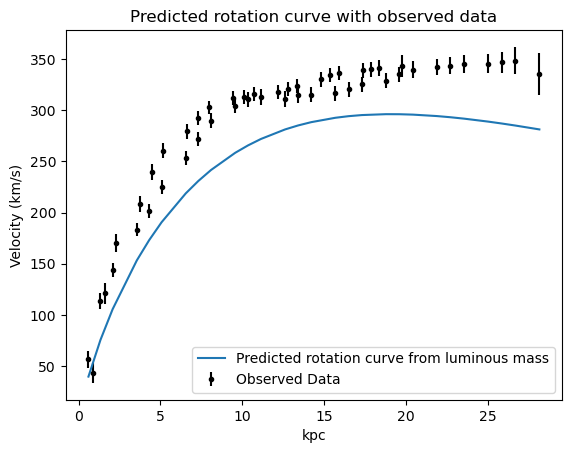

In [38]:
plt.errorbar(rFoldKpc, vCorrected, yerr=vErr, fmt='k.')
plt.plot(rKpcRight, vPredKms)
plt.title("Predicted rotation curve with observed data")
plt.xlabel('kpc')
plt.ylabel('Velocity (km/s)')
plt.legend(['Predicted rotation curve from luminous mass', 'Observed Data', ])
plt.savefig("pred rotation curve")
plt.show()